# 🧠 LangGraph 메모리 실전 가이드

## 이 강의에서 배울 내용

1. **MemorySaver** - RAM 기반 단기 메모리 (테스트용)
2. **SqliteSaver** - 파일 기반 영구 메모리 (실전용)
3. **InMemoryStore** - 구조화된 데이터 저장소 (업무 기록용)
4. **의미 기반 검색** - AI가 문맥을 이해하는 검색
5. **대화 요약 & 장기 기억** - 대화를 요약하고 영구 보관

---

#  환경 설정

필요한 패키지를 설치합니다.

In [ ]:
# 필수 패키지 설치
! uv  pip install -q --upgrade langgraph langchain langchain_google_genai \
    langgraph-checkpoint-sqlite langchain-huggingface sentence-transformers

In [1]:
from dotenv import load_dotenv

load_dotenv()

True

# LLM 초기화

In [19]:
from langchain_core.rate_limiters import InMemoryRateLimiter  # 메모리 기반 속도 제한기 클래스
from langchain.chat_models import init_chat_model  # 모델명 문자열로 챗 모델을 초기화하는 함수

# 호출 제한 설정 (분당 10회)
rate_limiter = InMemoryRateLimiter(
    requests_per_second=0.167,   # 초당 허용 요청 수 (0.167회/초 ≈ 10회/분)
    check_every_n_seconds=0.1,   # 토큰(요청 허가) 사용 가능 여부를 0.1초마다 확인
    max_bucket_size=10           # 버킷에 누적 가능한 최대 토큰 수 (한 번에 몰아서 보낼 수 있는 최대 요청 수)
)

# LLM 초기화 (rate_limiter를 연결하여 모든 호출에 속도 제한 적용)
llm = init_chat_model(
    model="gpt-5-mini",          # 사용할 모델명
    rate_limiter=rate_limiter    # 위에서 생성한 속도 제한기 전달
)

print("✅ LLM 초기화 완료")

✅ LLM 초기화 완료


---

#  MemorySaver - 단기 메모리

## 🎯 학습 목표
- 대화 맥락을 기억하는 그래프 만들기
- 메모리 히스토리 확인하기
- 과거 시점으로 되돌리기

### 핵심 개념
- **MemorySaver**: RAM에 임시 저장 (세션 종료 시 삭제)
- **State**: 대화 메시지를 저장하는 그래프의 상태
- **Checkpoint**: 특정 시점의 상태 스냅샷

In [20]:
from typing import Annotated  # 타입에 메타데이터(리듀서)를 부착하기 위한 도구
from typing_extensions import TypedDict  # 상태 스키마 정의용 딕셔너리 타입
from langgraph.graph import StateGraph, START, END  # 그래프 빌더와 시작/종료 노드 상수
from langgraph.graph.message import add_messages  # 메시지 리스트 누적 리듀서
from langgraph.checkpoint.memory import MemorySaver  # 인메모리 체크포인터 클래스
from langchain_core.messages import HumanMessage  # 사용자 메시지 클래스 (이 코드에서는 미사용)

# Step 1: 상태 정의 (대화 메시지를 담는 구조)
class State(TypedDict):
    messages: Annotated[list, add_messages]  # add_messages 리듀서로 메시지를 덮어쓰지 않고 누적

# Step 2: LLM 호출 노드
def call_model(state: State):
    """사용자 메시지를 받아 LLM 응답 생성"""
    response = llm.invoke(state["messages"])  # 현재까지의 메시지 전체를 LLM에 전달
    return {"messages": response}  # 응답 메시지를 상태에 추가 (리듀서가 리스트에 누적)

# Step 3: 그래프 구성
builder = StateGraph(State)                  # 상태 스키마 기반 그래프 빌더 생성
builder.add_node("call_model", call_model)   # LLM 호출 노드 등록
builder.add_edge(START, "call_model")        # 시작점에서 call_model 노드로 연결

# Step 4: 메모리 체크포인터 추가
memory = MemorySaver()  # 인메모리 체크포인터 생성 (프로세스 종료 시 데이터 소멸)
graph = builder.compile(checkpointer=memory)  # 체크포인터를 연결하여 그래프 컴파일

print("✅ 메모리 그래프 구성 완료")

✅ 메모리 그래프 구성 완료


## 실습: 대화하고 기억 확인하기

In [21]:
# 대화 설정 (thread_id로 대화 세션 식별, 같은 ID를 쓰면 이전 대화가 이어짐)
config = {"configurable": {"thread_id": "conversation-001"}}

# 첫 번째 질문 메시지 생성
input_msg = HumanMessage("안녕하세요! 저는 파이썬을 배우고 있어요")

# 그래프 실행 및 스트리밍 출력
# stream_mode="values": 각 단계 실행 후 전체 상태(state) 값을 반환
for chunk in graph.stream({"messages": [input_msg]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()  # 상태의 마지막 메시지를 보기 좋게 출력

print("\n" + "="*50 + "\n")  # 구분선 출력

================================ Human Message =================================

안녕하세요! 저는 파이썬을 배우고 있어요
================================== Ai Message ==================================

반가워요! 파이썬 배우고 계시다니 좋네요. 제가 도와드릴게요 — 먼저 몇 가지 질문과 함께 짧은 가이드/추천을 드릴게요.

질문
- 지금 초보(처음)인가요, 아니면 어느 정도 문법을 아는 상태인가요?
- 배우려는 목적(데이터분석, 웹개발, 자동화, 알고리즘 등)이 있으신가요?

기본 학습 순서(초보 기준)
1. 개발환경 설치: Python 설치(최신 3.x), 편집기: VS Code 또는 PyCharm, Jupyter Notebook(데이터 분석 시 유용).
2. 기초 문법: 변수, 자료형(str, int, float, list, dict, tuple, set), 연산자, 입력/출력.
3. 제어문: if, for, while, 리스트 컴프리헨션.
4. 함수와 모듈: 함수 정의, 인자, 반환값, 표준 라이브러리 사용법, pip로 패키지 설치.
5. 파일 입출력과 예외 처리.
6. 객체지향 기본: 클래스, 상속, 메서드.
7. 프로젝트/심화: 웹(Flask/Django), 데이터(Numpy/Pandas/Matplotlib), 자동화(Requests/BeautifulSoup/Selenium), 알고리즘 연습.

추천 학습 자료
- 한국어: 생활코딩 파이썬 강의, "점프 투 파이썬"
- 영어: Python 공식 튜토리얼, Automate the Boring Stuff with Python(자동화 예제 좋음), Real Python
- 연습 문제: 백준(한국), CodeUp, Codewars, LeetCode, HackerRank

초간단 예제(기본)
- 출력과 함수 예시:
```python
def greet(name):
    return

In [22]:
# 두 번째 질문 (이전 대화 기억 테스트)
# 딕셔너리 형식(role/content)으로 메시지 전달 (HumanMessage 객체와 동일하게 처리됨)
followup = {"role": "user", "content": "방금 제가 뭐라고 했죠?"}

# 같은 config(thread_id="conversation-001")를 사용하므로 이전 대화 이력이 이어짐
for chunk in graph.stream({"messages": [followup]}, config, stream_mode="values"):
    chunk["messages"][-1].pretty_print()  # 상태의 마지막 메시지를 보기 좋게 출력

================================ Human Message =================================

방금 제가 뭐라고 했죠?
================================== Ai Message ==================================

방금 "안녕하세요! 저는 파이썬을 배우고 있어요"라고 하셨어요.


## 메모리 히스토리 확인

In [23]:
# 현재 상태 확인 (해당 thread_id의 최신 체크포인트 조회)
current_state = graph.get_state(config)
print("📝 현재 메시지 수:", len(current_state.values['messages']))  # 누적된 전체 메시지 개수
print("\n최근 메시지:")
current_state.values['messages'][-1].pretty_print()  # 가장 마지막 메시지(최신 AI 응답) 출력

# 전체 히스토리 확인 (해당 thread_id의 모든 체크포인트를 최신순으로 조회)
history = list(graph.get_state_history(config))
print(f"\n💾 저장된 체크포인트 수: {len(history)}")

# 각 체크포인트 시점의 메시지 개수 출력
for i, h in enumerate(history):
    print(f"  [{i}] 메시지 {len(h.values['messages'])}개")

📝 현재 메시지 수: 4

최근 메시지:
================================== Ai Message ==================================

방금 "안녕하세요! 저는 파이썬을 배우고 있어요"라고 하셨어요.

💾 저장된 체크포인트 수: 6
  [0] 메시지 4개
  [1] 메시지 3개
  [2] 메시지 2개
  [3] 메시지 2개
  [4] 메시지 1개
  [5] 메시지 0개


## 과거 시점으로 되돌리기

In [7]:
# 두 번째 체크포인트로 되돌리기
if len(history) > 1:
    # 해당 시점으로 재실행
    result = graph.invoke(None, config=history[2].config)
    print(result)


{'messages': [HumanMessage(content='안녕하세요! 저는 파이썬을 배우고 있어요', additional_kwargs={}, response_metadata={}, id='79619d8a-29a0-4b9f-aae3-d1fa92cbcf57'), AIMessage(content='안녕하세요! 반가워요 — 파이썬 배우신다니 좋아요. 어떻게 도와드릴까요? (초보 기초, 문제 풀이, 프로젝트 아이디어, 디버깅 등 원하시는 걸 알려주세요.)\n\n간단 가이드와 예제 정리해드릴게요.\n\n1) 시작 체크리스트\n- Python 3 설치 (python.org 또는 패키지 매니저)\n- 코드 에디터: VS Code, PyCharm, 또는 Jupyter Notebook(데이터 작업 시 유용)\n- 가상환경 권장: python -m venv venv && source venv/bin/activate (Windows: venv\\Scripts\\activate)\n- 패키지 설치: pip install 패키지명\n\n2) 아주 기본 예제들\n- Hello world\n  print("Hello, world!")\n\n- 변수와 타입\n  x = 10      # 정수\n  y = 3.14    # 실수\n  name = "철수"  # 문자열\n  is_ok = True   # 불리언\n\n- 조건문\n  if x > 5:\n      print("x는 5보다 큽니다")\n  else:\n      print("x는 5 이하입니다")\n\n- 반복문과 리스트\n  nums = [1, 2, 3, 4]\n  for n in nums:\n      print(n)\n\n- 함수\n  def add(a, b):\n      return a + b\n\n  print(add(2, 3))  # 5\n\n- 리스트 내포 (간단하고 파이썬스러운 표현)\n  squares = [n*n for n in range(1, 6)]  # [1,4,9,16,25]\n\n3) 파일로 실행

---

#  InMemoryStore - 구조화된 데이터 저장

## 🎯 학습 목표
- 대화 외 업무 데이터 저장하기
- 네임스페이스로 데이터 분류하기
- ID 기반 검색 및 업데이트

### 용도 예시
- 고객 케이스 기록
- 캠페인 정보
- 업무 메모

In [27]:
from langgraph.store.memory import InMemoryStore  # 인메모리 기반 장기 메모리 저장소 클래스
import uuid  # 고유 ID 생성용 표준 라이브러리

# 메모리 저장소 생성
store = InMemoryStore()

# 네임스페이스 설정 (튜플 형태의 계층 구조: 회사명, 카테고리)
namespace = ('MyCompany', 'customer_cases')

# 데이터 저장
case_id = str(uuid.uuid4())  # 저장할 항목의 고유 키 생성
case_data = {
    'customer_name': '홍길동',
    'issue': '로그인 문제',
    'status': '진행중'
}
store.put(namespace, case_id, case_data)  # (네임스페이스, 키, 값) 형태로 저장

print("✅ 데이터 저장 완료")
print(f"   ID: {case_id}")
print(f"   내용: {case_data}")

✅ 데이터 저장 완료
   ID: 06faa6bb-ea16-42d8-b5e3-37b51ee23ab3
   내용: {'customer_name': '홍길동', 'issue': '로그인 문제', 'status': '진행중'}


## 데이터 검색 및 관리

In [28]:
# 여러 데이터 추가
cases = [
    {'customer_name': '김철수', 'issue': '결제 오류', 'status': '완료'},
    {'customer_name': '이영희', 'issue': '배송 지연', 'status': '진행중'},
    {'customer_name': '박민수', 'issue': '환불 요청', 'status': '대기'}
]

# 각 케이스를 고유 ID를 키로 하여 같은 네임스페이스에 저장
for case in cases:
    store.put(namespace, str(uuid.uuid4()), case)

# 네임스페이스 내 전체 항목 검색
results = store.search(namespace)

# 검색 결과 출력 (각 항목의 실제 데이터는 item.value에 저장됨)
print("📋 저장된 케이스 목록:\n")
for i, item in enumerate(results, 1):
    print(f"{i}. {item.value['customer_name']} - {item.value['issue']} ({item.value['status']})")

📋 저장된 케이스 목록:

1. 홍길동 - 로그인 문제 (진행중)
2. 김철수 - 결제 오류 (완료)
3. 이영희 - 배송 지연 (진행중)
4. 박민수 - 환불 요청 (대기)


## 데이터 업데이트

In [29]:
# 첫 번째 케이스 상태 변경
if results:  # 검색 결과가 비어 있지 않은 경우에만 실행
    first_case_id = results[0].key  # 첫 번째 항목의 고유 키 가져오기
    updated_data = results[0].value.copy()  # 원본 딕셔너리를 복사하여 수정용 사본 생성
    updated_data['status'] = '완료'  # 상태 필드만 변경

    # 같은 네임스페이스 + 같은 키로 put하면 기존 값을 덮어씀 (업데이트 동작)
    store.put(namespace, first_case_id, updated_data)
    print(f"✅ 케이스 업데이트 완료: {updated_data['customer_name']} - {updated_data['status']}")

    # 업데이트 결과 확인
    updated = store.search(namespace)
    print("\n📋 업데이트된 목록:")
    for item in updated[:3]:  # 앞에서 3개 항목만 출력
        print(f"  - {item.value['customer_name']}: {item.value['status']}")

✅ 케이스 업데이트 완료: 홍길동 - 완료

📋 업데이트된 목록:
  - 홍길동: 완료
  - 김철수: 완료
  - 이영희: 진행중


---

#  Use semantic search  의미 기반 검색

## 🎯 학습 목표
- 문장의 의미를 이해하는 검색 구현
- 임베딩 모델 활용
- 유사도 기반 검색

### 키워드 검색 vs 의미 검색

**키워드 검색**: "봄 프로모션" → "봄", "프로모션" 단어가 있어야 찾음

**의미 검색**: "봄 프로모션" → "2025 Spring 이벤트", "봄 할인 행사" 등 의미가 비슷하면 찾음

In [30]:
from langchain.embeddings import init_embeddings  # 문자열 식별자로 임베딩 모델을 초기화하는 함수
from langgraph.store.memory import InMemoryStore  # 인메모리 저장소 클래스 (이 셀에서는 미사용, 다음 단계에서 사용 예정)

# 의미 검색용 임베딩 모델 생성
# "openai:text-embedding-3-small" 형식 = "제공자:모델명"
embeddings = init_embeddings("openai:text-embedding-3-small")

print("✅ 임베딩 모델 준비 완료")

✅ 임베딩 모델 준비 완료


## 의미 검색 저장소 생성

In [31]:
# 벡터 검색 가능한 저장소 생성
vector_store = InMemoryStore(
    index={
        "embed": embeddings,     # 이전 셀에서 만든 임베딩 모델 연결
        "dims": 1536,            # text-embedding-3-small 모델의 출력 차원
        "fields": ["content"]    # 임베딩(검색) 대상으로 삼을 필드 지정
    }
)

# 테스트 데이터 추가
namespace = ('company', 'announcements')  # 네임스페이스 설정 (회사, 공지사항)

announcements = [
    {'title': '신규 고객 환영', 'content': '신규 가입 고객을 위한 특별 할인 이벤트'},
    {'title': '봄 프로모션', 'content': '2025년 봄 시즌 특별 프로모션 안내'},
    {'title': '시스템 점검', 'content': '정기 시스템 점검 일정 공지'},
    {'title': 'VIP 혜택', 'content': 'VIP 고객을 위한 전용 혜택 안내'}
]

# 각 공지를 저장 (put 시점에 content 필드가 자동으로 임베딩되어 인덱싱됨)
for announcement in announcements:
    vector_store.put(namespace, str(uuid.uuid4()), announcement)

print("✅ 의미 검색 데이터 준비 완료")

✅ 의미 검색 데이터 준비 완료


## 의미 기반 검색 실행

In [32]:
# 자연어 질의로 의미 검색
query = "VIP 혜택 내용이 있나요?"

# query 인자를 넘기면 질의를 임베딩하여 유사도 기반으로 검색
results = vector_store.search(
    namespace,   # 검색 대상 네임스페이스
    query=query, # 자연어 질의 (임베딩되어 저장된 벡터들과 비교됨)
    limit=3      # 상위 3개 결과만 반환
)

print(f"🔍 질의: '{query}'\n")
print("검색 결과 (유사도 순):\n")

# 각 결과의 제목, 내용, 유사도 점수 출력
for i, result in enumerate(results, 1):
    score = result.score if hasattr(result, 'score') else 0  # score 속성이 없는 경우 0으로 대체
    print(f"{i}. {result.value['title']}")
    print(f"   내용: {result.value['content']}")
    print(f"   유사도: {score:.3f}\n")

🔍 질의: 'VIP 혜택 내용이 있나요?'

검색 결과 (유사도 순):

1. VIP 혜택
   내용: VIP 고객을 위한 전용 혜택 안내
   유사도: 0.643

2. 신규 고객 환영
   내용: 신규 가입 고객을 위한 특별 할인 이벤트
   유사도: 0.346

3. 봄 프로모션
   내용: 2025년 봄 시즌 특별 프로모션 안내
   유사도: 0.262



---

#  대화 요약 & 장기 기억

## 🎯 학습 목표
- 대화 종료 시 자동 요약
- 요약본 장기 저장
- 다음 대화 시 이전 요약 활용

### 동작 흐름
1. 사용자와 대화
2. "END" 입력 시 대화 요약
3. 요약을 사용자별 저장소에 보관
4. 다음 대화 시 이전 요약 참고

In [33]:
from langchain_core.messages import SystemMessage, RemoveMessage  # 시스템 메시지, 메시지 삭제 마커 클래스
from langgraph.store.base import BaseStore  # 스토어 타입 힌트용 베이스 클래스
from langchain_core.runnables import RunnableConfig  # 실행 설정(config) 타입 힌트용 클래스

# 상태 정의
class ConversationState(TypedDict):
    messages: Annotated[list, add_messages]  # add_messages 리듀서로 메시지 누적/삭제 처리
    summary: str                              # 대화 요약문 저장 필드

# 장기 메모리 저장소 생성
memory_store = InMemoryStore()

# 노드 1: AI 응답 생성
def chat_node(state: ConversationState, config: RunnableConfig, store: BaseStore):
    """이전 요약을 참고하여 응답 생성"""
    user_id = config['configurable']['user_id']  # config에서 사용자 ID 추출
    namespace = (user_id, 'summaries')           # 사용자별 요약 네임스페이스

    # 스토어에서 이전 대화 요약들 불러오기
    past_summaries = store.search(namespace)
    summary_text = "\n".join([
        f"- {item.value.get('summary', '')}"
        for item in past_summaries
        if 'summary' in item.value
    ])

    # 이전 요약을 포함한 시스템 프롬프트 구성
    system_msg = SystemMessage(content=f"""
당신은 친절한 AI 어시스턴트입니다.
이전 대화 요약:
{summary_text if summary_text else '(이전 대화 없음)'}
위 정보를 참고하여 일관성 있게 답변하세요.
""")

    # 시스템 메시지 + 현재까지의 대화를 LLM에 전달
    messages = [system_msg] + state['messages']
    response = llm.invoke(messages)
    print("\n🤖 AI:", response.content)

    # 콘솔에서 다음 사용자 입력 받기
    user_input = input("\n💬 You (종료하려면 'END' 입력): ")
    user_message = HumanMessage(content=user_input)

    # AI 응답과 새 사용자 메시지를 함께 상태에 추가
    return {"messages": [response, user_message]}

# 노드 2: 대화 요약
def summarize_node(state: ConversationState, config: RunnableConfig, store: BaseStore):
    """대화 내용을 요약"""
    summary_prompt = HumanMessage(content="""
지금까지의 대화를 3-5문장으로 요약해주세요.
핵심 내용만 간결하게 정리하세요.
""")
    # 마지막 메시지('END' 입력)를 제외하고 요약 요청 메시지 추가
    messages = state['messages'][:-1] + [summary_prompt]
    summary = llm.invoke(messages)

    # 모든 메시지에 대한 삭제 마커 생성 (add_messages 리듀서가 해당 id 메시지를 제거)
    delete_markers = [RemoveMessage(id=m.id) for m in state['messages']]

    return {
        'summary': summary.content,   # 요약문을 상태에 저장
        'messages': delete_markers    # 기존 메시지 전체 삭제
    }

# 노드 3: 요약 저장
def save_summary_node(state: ConversationState, config: RunnableConfig, store: BaseStore):
    """요약을 장기 저장소에 보관"""
    user_id = config['configurable']['user_id']
    namespace = (user_id, 'summaries')

    summary_id = str(uuid.uuid4())  # 요약 항목의 고유 키 생성
    store.put(namespace, summary_id, {'summary': state['summary']})  # 스토어에 요약 저장
    print(f"\n💾 요약 저장 완료: {state['summary'][:50]}...")

# 조건 분기: 종료 여부 판단
def should_continue(state: ConversationState):
    """END 입력 시 요약 단계로, 아니면 대화 계속"""
    last_message = state['messages'][-1]
    if last_message.content.upper() == 'END':  # 대소문자 무관하게 END 판별
        return 'summarize'
    return 'continue'

print("✅ 대화 요약 노드 정의 완료")

✅ 대화 요약 노드 정의 완료


## 그래프 구성 및 실행

In [34]:
# 그래프 빌드
conversation_builder = StateGraph(ConversationState)  # 상태 스키마 기반 그래프 빌더 생성

# 노드 추가
conversation_builder.add_node('chat', chat_node)                  # 대화(응답 생성 + 입력 수집) 노드
conversation_builder.add_node('summarize', summarize_node)        # 대화 요약 노드
conversation_builder.add_node('save_summary', save_summary_node)  # 요약을 장기 저장소에 저장하는 노드

# 엣지 연결
conversation_builder.add_edge(START, 'chat')  # 시작점에서 chat 노드로 진입

# chat 노드 실행 후 should_continue의 반환값에 따라 분기
conversation_builder.add_conditional_edges(
    'chat',
    should_continue,
    {
        'continue': 'chat',       # 'continue' 반환 시 chat 노드로 되돌아가 대화 계속 (자기 순환)
        'summarize': 'summarize'  # 'summarize' 반환 시 요약 단계로 이동
    }
)
conversation_builder.add_edge('summarize', 'save_summary')  # 요약 완료 후 저장 노드로
conversation_builder.add_edge('save_summary', END)          # 저장 완료 후 그래프 종료

# 컴파일 (체크포인터 = 단기 메모리, 스토어 = 장기 메모리 동시 연결)
conversation_graph = conversation_builder.compile(
    checkpointer=memory,   # MemorySaver: thread별 대화 상태 저장
    store=memory_store     # InMemoryStore: 사용자별 요약 영구 보관 (노드의 store 파라미터로 주입됨)
)

print("✅ 대화 요약 그래프 구성 완료\n")

✅ 대화 요약 그래프 구성 완료



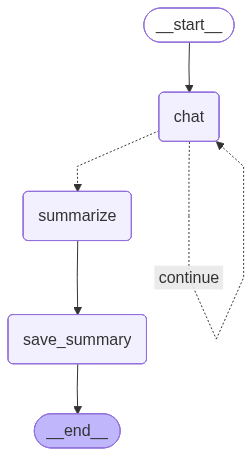

In [35]:
conversation_graph

## 실습: 요약 기능이 있는 대화

In [36]:
print("💬 대화를 시작합니다. 종료하려면 'END'를 입력하세요.\n")

# 실행 설정 (thread_id: 체크포인터용 세션 ID, user_id: 스토어 네임스페이스용 사용자 ID)
config = {
    'configurable': {
        'thread_id': 'session-001',
        'user_id': 'user_kim'
    },
    'recursion_limit': 100  # chat 노드 자기 순환에 대비해 super-step 한도 상향 (기본값 25)
}

# 첫 메시지를 콘솔에서 입력받아 HumanMessage로 변환
first_msg = input("💬 You: ")
initial_messages = [HumanMessage(content=first_msg)]

# 그래프 실행
# stream_mode="updates": 각 노드 실행 후 변경분만 이벤트로 반환
for event in conversation_graph.stream(
    {'messages': initial_messages},
    config,
    stream_mode="updates"
):
    pass  # 화면 출력은 노드 내부의 print/input에서 처리하므로 이벤트는 사용하지 않음

💬 대화를 시작합니다. 종료하려면 'END'를 입력하세요.


🤖 AI: 안녕하세요! 만나서 반가워요. 무엇을 도와드릴까요?

🤖 AI: 지금 바로 실시간 기상 정보를 조회할 수는 없어요. 대신 빠르게 확인하는 방법과 오늘 서울에 적용될 가능성이 높은 일반적 특징과 준비물은 알려드릴게요.

빠르게 날씨 확인하는 방법
- 기상청: https://www.kma.go.kr  
- 네이버 날씨: https://weather.naver.com (서울 검색)  
- 스마트폰 기본 날씨 앱이나 Google에 "서울 날씨" 검색

7월(오늘 기준)에 서울에서 흔한 날씨 — 요약/팁
- 계절: 한여름, 덥고 습함(평균 낮 28–33°C, 밤 22–26°C 정도).  
- 장마/소나기 가능성: 6–7월 장마철 영향으로 국지성 강한 비가 올 수 있음.  
- 준비물: 얇은 통풍성 옷, 자외선 차단제, 선글라스, 모자, 휴대용 선풍기/물, 우산 또는 방수 겉옷.  
- 외출 팁: 더위·소나기 대비로 가벼운 우산과 물 챙기기, 실외 활동은 오전·저녁이 상대적으로 쾌적함.

원하시면 지금 바로(제가 실시간 검색은 못 하지만) 특정 시간대 예상 기온·강수확률을 알려드릴 수 있도록 사용 중인 기상 정보(예: 현재 온도/강수표시)를 붙여 주시거나, 제가 추천하는 사이트에서 바로 확인하는 법을 더 자세히 안내해드릴게요. 어떻게 도와드릴까요?

💾 요약 저장 완료: 1. 사용자가 인사하자 어시스턴트가 인사로 응답하고 도움을 물었습니다.  
2. 사용자가 ...


## 저장된 요약 확인

In [37]:
# 사용자별 요약 조회
user_namespace = ('user_kim', 'summaries')
saved_summaries = memory_store.search(user_namespace)

print("\n📚 저장된 대화 요약 목록:\n")
for i, item in enumerate(saved_summaries, 1):
    print(f"{i}. {item.value.get('summary', '')}")
    print(f"   (저장 시간: {item.created_at})\n")


📚 저장된 대화 요약 목록:

1. 1. 사용자가 인사하자 어시스턴트가 인사로 응답하고 도움을 물었습니다.  
2. 사용자가 "오늘 서울 날씨"를 물었고, 어시스턴트는 실시간 조회는 불가하다고 답하며 기상청·네이버·스마트폰 앱 등 확인 방법을 제시했습니다.  
3. 어시스턴트는 7월 서울의 일반적 특징(무덥고 습함, 장마·소나기 가능성), 준비물(얇은 통풍 옷·자외선 차단제·우산 등)을 안내하고 추가 도움(구체적 예보 안내)은 요청받으면 제공하겠다고 했습니다.
   (저장 시간: 2026-07-14 10:53:47.473613+00:00)

